In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import random
import matplotlib.pyplot as plt
import pandas as pd

from torch.utils.data import DataLoader, Subset

SEED = 42
BATCH_SIZE = 64
NUM_EPOCHS = 10
LEARNING_RATE = 0.001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Seed:", SEED)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)
print("Learning Rate:", LEARNING_RATE)


Device: cpu
Seed: 42
Batch Size: 64
Epochs: 10
Learning Rate: 0.001


In [2]:
import torch
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, Subset

In [4]:
# STEP 2: CIFAR-10 Dataset Preparation

import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

# Fallback configurations in case the setup cell wasn't run or memory was cleared
if 'SEED' not in globals():
    SEED = 42
if 'BATCH_SIZE' not in globals():
    BATCH_SIZE = 64

# Normal preprocessing
normal_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

# Augmentation for training images only
augmentation_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

# Load original training dataset
full_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=normal_transform
)

# Load separately for augmented training
full_aug_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=augmentation_transform
)

# Load original test dataset
test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=normal_transform
)

# Reproduce Exercise 1 split
generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(
    len(full_train_dataset),
    generator=generator
).tolist()

train_indices = indices[:40000]
val_indices = indices[40000:]

# Create separate datasets
train_dataset = Subset(
    full_train_dataset, train_indices
)

val_dataset = Subset(
    full_train_dataset, val_indices
)

aug_train_dataset = Subset(
    full_aug_dataset, train_indices
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

aug_train_loader = DataLoader(
    aug_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

# Display information
print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))
print("Augmented Training Images:", len(aug_train_dataset))

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))
print("Augmented Training Batches:", len(aug_train_loader))

Training Images: 40000
Validation Images: 10000
Testing Images: 10000
Augmented Training Images: 40000
Training Batches: 625
Validation Batches: 157
Testing Batches: 157
Augmented Training Batches: 625


In [6]:

# STEP 3: Define Baseline CNN Model
# Same architecture as Exercise 2

import torch
import torch.nn as nn
import torch.nn.functional as F

# Fallback definition for device in case the setup cell wasn't run in this session
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class CNNClassifier(nn.Module):
    def __init__(self):
        super(CNNClassifier, self).__init__()

        # Trainable Layer 1
        self.conv1 = nn.Conv2d(
            3, 32, kernel_size=3, padding=1
        )

        # Trainable Layer 2
        self.conv2 = nn.Conv2d(
            32, 64, kernel_size=3, padding=1
        )

        # Trainable Layer 3
        self.fc = nn.Linear(64 * 8 * 8, 10)

        # Max Pooling
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = self.fc(x)

        return x


# Create Baseline CNN Model
baseline_model = CNNClassifier().to(device)

# Display architecture
print("Baseline CNN Architecture:")
print(baseline_model)

# Count trainable parameters
total_params = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)

print("\nTotal Trainable Parameters:", total_params)

Baseline CNN Architecture:
CNNClassifier(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc): Linear(in_features=4096, out_features=10, bias=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)

Total Trainable Parameters: 60362


In [7]:

# STEP 4: Training and Evaluation Functions

import torch
import torch.nn as nn
import torch.optim as optim

# Evaluate a model
def evaluate_model(model, data_loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    return avg_loss, accuracy


# Train a model
def train_model(model, train_loader, val_loader, epochs=10):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / total
        train_acc = 100 * correct / total

        val_loss, val_acc = evaluate_model(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )

    return history


print("Training and Evaluation Functions Ready!")


Training and Evaluation Functions Ready!


In [9]:
# STEP 5: Train Baseline CNN

# Fallback configurations in case the setup cell wasn't run in this session
if 'NUM_EPOCHS' not in globals():
    NUM_EPOCHS = 10
if 'LEARNING_RATE' not in globals():
    LEARNING_RATE = 0.001

print("Starting Baseline CNN Training...")

baseline_history = train_model(
    baseline_model,
    train_loader,
    val_loader,
    epochs=NUM_EPOCHS
)

print("\nBaseline CNN Training Completed!")

Starting Baseline CNN Training...
Epoch [1/10] Train Loss: 1.3560 | Train Acc: 52.09% | Val Loss: 1.0908 | Val Acc: 61.88%
Epoch [2/10] Train Loss: 0.9881 | Train Acc: 65.69% | Val Loss: 0.9771 | Val Acc: 66.00%
Epoch [3/10] Train Loss: 0.8595 | Train Acc: 70.44% | Val Loss: 0.8827 | Val Acc: 69.62%
Epoch [4/10] Train Loss: 0.7742 | Train Acc: 73.28% | Val Loss: 0.9446 | Val Acc: 66.89%
Epoch [5/10] Train Loss: 0.7078 | Train Acc: 75.54% | Val Loss: 0.8601 | Val Acc: 70.88%
Epoch [6/10] Train Loss: 0.6499 | Train Acc: 77.64% | Val Loss: 0.8772 | Val Acc: 70.03%
Epoch [7/10] Train Loss: 0.5973 | Train Acc: 79.18% | Val Loss: 0.8989 | Val Acc: 69.66%
Epoch [8/10] Train Loss: 0.5518 | Train Acc: 80.76% | Val Loss: 0.8843 | Val Acc: 70.64%
Epoch [9/10] Train Loss: 0.5138 | Train Acc: 82.11% | Val Loss: 0.9147 | Val Acc: 70.46%
Epoch [10/10] Train Loss: 0.4813 | Train Acc: 83.26% | Val Loss: 0.9333 | Val Acc: 70.52%

Baseline CNN Training Completed!


In [10]:

# STEP 6: Baseline CNN Test Evaluation

criterion = nn.CrossEntropyLoss()

# Evaluate on original training images
train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

baseline_train_loss, baseline_train_acc = evaluate_model(
    baseline_model,
    train_eval_loader,
    criterion
)

# Evaluate on test dataset
baseline_test_loss, baseline_test_acc = evaluate_model(
    baseline_model,
    test_loader,
    criterion
)

# Calculate generalisation gap
baseline_gap = baseline_train_acc - baseline_test_acc

print("Baseline CNN Final Results")
print("--------------------------")
print(f"Training Accuracy: {baseline_train_acc:.2f}%")
print(f"Test Accuracy: {baseline_test_acc:.2f}%")
print(f"Generalisation Gap: {baseline_gap:.2f} percentage points")
print(f"Test Loss: {baseline_test_loss:.4f}")


Baseline CNN Final Results
--------------------------
Training Accuracy: 86.67%
Test Accuracy: 69.70%
Generalisation Gap: 16.97 percentage points
Test Loss: 0.9537


In [11]:

# STEP 7: CNN with Dropout

import torch
import torch.nn as nn
import torch.nn.functional as F

class DropoutCNN(nn.Module):
    def __init__(self):
        super(DropoutCNN, self).__init__()

        # Layer 1
        self.conv1 = nn.Conv2d(
            3, 32, kernel_size=3, padding=1
        )

        # Layer 2
        self.conv2 = nn.Conv2d(
            32, 64, kernel_size=3, padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)

        # Dropout regularisation
        self.dropout = nn.Dropout(p=0.3)

        # Layer 3
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = self.fc(x)

        return x


# Create Dropout CNN model
torch.manual_seed(SEED)
dropout_model = DropoutCNN().to(device)

print("Dropout CNN Architecture:")
print(dropout_model)

dropout_params = sum(
    p.numel()
    for p in dropout_model.parameters()
    if p.requires_grad
)

print("\nTotal Trainable Parameters:", dropout_params)


Dropout CNN Architecture:
DropoutCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)

Total Trainable Parameters: 60362


In [12]:

# STEP 8: Train Dropout CNN

print("Starting Dropout CNN Training...")

dropout_history = train_model(
    dropout_model,
    train_loader,
    val_loader,
    epochs=NUM_EPOCHS
)

print("\nDropout CNN Training Completed!")


Starting Dropout CNN Training...
Epoch [1/10] Train Loss: 1.4002 | Train Acc: 50.48% | Val Loss: 1.1039 | Val Acc: 61.96%
Epoch [2/10] Train Loss: 1.0637 | Train Acc: 63.03% | Val Loss: 0.9832 | Val Acc: 65.76%
Epoch [3/10] Train Loss: 0.9429 | Train Acc: 67.27% | Val Loss: 0.9270 | Val Acc: 67.03%
Epoch [4/10] Train Loss: 0.8671 | Train Acc: 69.81% | Val Loss: 0.8900 | Val Acc: 69.36%
Epoch [5/10] Train Loss: 0.8140 | Train Acc: 71.85% | Val Loss: 0.8443 | Val Acc: 70.16%
Epoch [6/10] Train Loss: 0.7701 | Train Acc: 73.32% | Val Loss: 0.8216 | Val Acc: 71.45%
Epoch [7/10] Train Loss: 0.7365 | Train Acc: 74.52% | Val Loss: 0.8143 | Val Acc: 71.47%
Epoch [8/10] Train Loss: 0.7099 | Train Acc: 75.26% | Val Loss: 0.8340 | Val Acc: 71.55%
Epoch [9/10] Train Loss: 0.6815 | Train Acc: 76.29% | Val Loss: 0.8116 | Val Acc: 72.32%
Epoch [10/10] Train Loss: 0.6583 | Train Acc: 77.01% | Val Loss: 0.8049 | Val Acc: 72.27%

Dropout CNN Training Completed!


In [13]:

# STEP 9: Dropout CNN Test Evaluation

criterion = nn.CrossEntropyLoss()

# Evaluate training accuracy
dropout_train_loss, dropout_train_acc = evaluate_model(
    dropout_model,
    train_eval_loader,
    criterion
)

# Evaluate test accuracy
dropout_test_loss, dropout_test_acc = evaluate_model(
    dropout_model,
    test_loader,
    criterion
)

# Calculate generalisation gap
dropout_gap = dropout_train_acc - dropout_test_acc

print("Dropout CNN Final Results")
print("--------------------------")
print(f"Training Accuracy: {dropout_train_acc:.2f}%")
print(f"Test Accuracy: {dropout_test_acc:.2f}%")
print(f"Generalisation Gap: {dropout_gap:.2f} percentage points")
print(f"Test Loss: {dropout_test_loss:.4f}")

print("\nBaseline vs Dropout Comparison")
print("--------------------------")
print(f"Baseline Test Accuracy: {baseline_test_acc:.2f}%")
print(f"Dropout Test Accuracy: {dropout_test_acc:.2f}%")
print(f"Baseline Gap: {baseline_gap:.2f} pp")
print(f"Dropout Gap: {dropout_gap:.2f} pp")


Dropout CNN Final Results
--------------------------
Training Accuracy: 83.15%
Test Accuracy: 72.76%
Generalisation Gap: 10.39 percentage points
Test Loss: 0.7952

Baseline vs Dropout Comparison
--------------------------
Baseline Test Accuracy: 69.70%
Dropout Test Accuracy: 72.76%
Baseline Gap: 16.97 pp
Dropout Gap: 10.39 pp


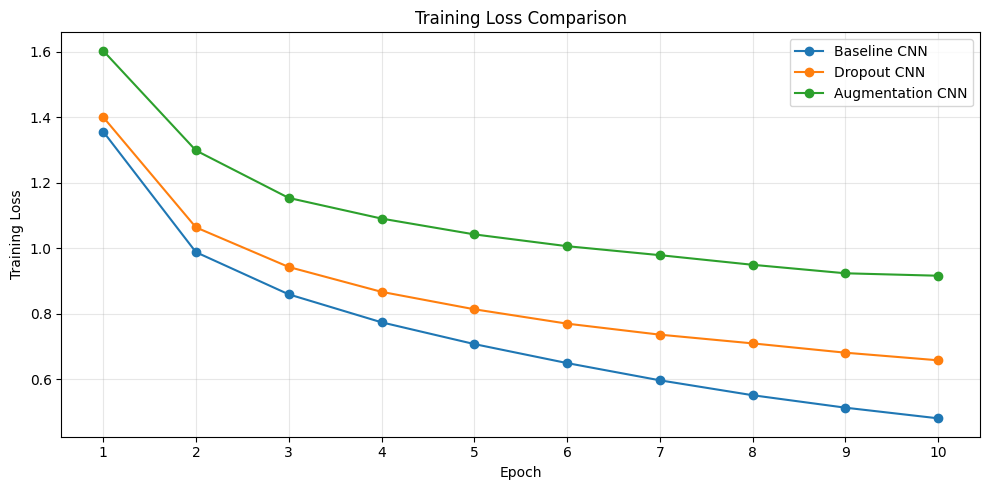

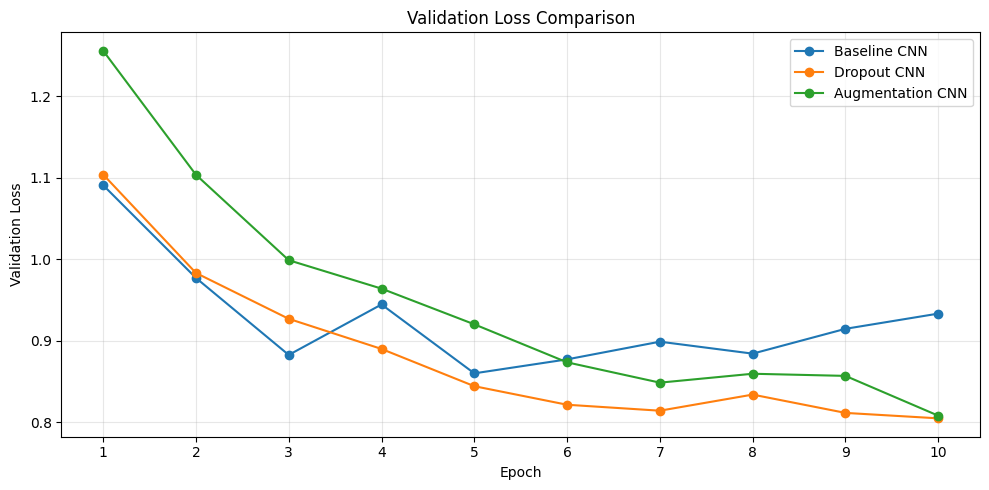

Corrected loss graphs saved successfully!


In [20]:

# STEP 15: Corrected Training and Validation Loss Graphs

import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)

# Graph 1: Training Loss Comparison
plt.figure(figsize=(10, 5))

plt.plot(epochs, baseline_history["train_loss"],
         marker="o", label="Baseline CNN")

plt.plot(epochs, dropout_history["train_loss"],
         marker="o", label="Dropout CNN")

plt.plot(epochs, augmentation_history["train_loss"],
         marker="o", label="Augmentation CNN")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("Exercise3_Training_Loss.png", dpi=300)
plt.show()


# Graph 2: Validation Loss Comparison
plt.figure(figsize=(10, 5))

plt.plot(epochs, baseline_history["val_loss"],
         marker="o", label="Baseline CNN")

plt.plot(epochs, dropout_history["val_loss"],
         marker="o", label="Dropout CNN")

plt.plot(epochs, augmentation_history["val_loss"],
         marker="o", label="Augmentation CNN")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("Exercise3_Validation_Loss.png", dpi=300)
plt.show()

print("Corrected loss graphs saved successfully!")


In [14]:

# STEP 10: Create CNN for Data Augmentation

# Reset random seed for reproducibility
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Use the original CNN architecture
# No dropout layer
augmentation_model = CNNClassifier().to(device)

print("Data Augmentation CNN Architecture:")
print(augmentation_model)

# Count trainable parameters
augmentation_params = sum(
    p.numel()
    for p in augmentation_model.parameters()
    if p.requires_grad
)

print("\nTotal Trainable Parameters:", augmentation_params)

print("\nAugmented Training Images:", len(aug_train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))


Data Augmentation CNN Architecture:
CNNClassifier(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc): Linear(in_features=4096, out_features=10, bias=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)

Total Trainable Parameters: 60362

Augmented Training Images: 40000
Validation Images: 10000
Testing Images: 10000


In [15]:

# STEP 11: Train CNN with Data Augmentation

print("Starting Data Augmentation CNN Training...")

augmentation_history = train_model(
    augmentation_model,
    aug_train_loader,
    val_loader,
    epochs=NUM_EPOCHS
)

print("\nData Augmentation CNN Training Completed!")


Starting Data Augmentation CNN Training...
Epoch [1/10] Train Loss: 1.6025 | Train Acc: 42.10% | Val Loss: 1.2557 | Val Acc: 55.30%
Epoch [2/10] Train Loss: 1.2982 | Train Acc: 53.76% | Val Loss: 1.1036 | Val Acc: 61.25%
Epoch [3/10] Train Loss: 1.1535 | Train Acc: 59.59% | Val Loss: 0.9988 | Val Acc: 64.74%
Epoch [4/10] Train Loss: 1.0906 | Train Acc: 61.63% | Val Loss: 0.9640 | Val Acc: 66.44%
Epoch [5/10] Train Loss: 1.0423 | Train Acc: 63.51% | Val Loss: 0.9202 | Val Acc: 67.81%
Epoch [6/10] Train Loss: 1.0064 | Train Acc: 64.89% | Val Loss: 0.8736 | Val Acc: 69.95%
Epoch [7/10] Train Loss: 0.9790 | Train Acc: 65.59% | Val Loss: 0.8487 | Val Acc: 70.32%
Epoch [8/10] Train Loss: 0.9496 | Train Acc: 66.96% | Val Loss: 0.8596 | Val Acc: 70.54%
Epoch [9/10] Train Loss: 0.9237 | Train Acc: 67.81% | Val Loss: 0.8570 | Val Acc: 70.46%
Epoch [10/10] Train Loss: 0.9163 | Train Acc: 68.13% | Val Loss: 0.8082 | Val Acc: 71.79%

Data Augmentation CNN Training Completed!


In [16]:

# STEP 12: Data Augmentation CNN Evaluation

criterion = nn.CrossEntropyLoss()

# Evaluate on original training images
augmentation_train_loss, augmentation_train_acc = evaluate_model(
    augmentation_model,
    train_eval_loader,
    criterion
)

# Evaluate on test images
augmentation_test_loss, augmentation_test_acc = evaluate_model(
    augmentation_model,
    test_loader,
    criterion
)

# Calculate generalisation gap
augmentation_gap = (
    augmentation_train_acc - augmentation_test_acc
)

print("Data Augmentation CNN Final Results")
print("-----------------------------------")
print(f"Training Accuracy: {augmentation_train_acc:.2f}%")
print(f"Test Accuracy: {augmentation_test_acc:.2f}%")
print(f"Generalisation Gap: {augmentation_gap:.2f} percentage points")
print(f"Test Loss: {augmentation_test_loss:.4f}")


Data Augmentation CNN Final Results
-----------------------------------
Training Accuracy: 73.69%
Test Accuracy: 72.33%
Generalisation Gap: 1.36 percentage points
Test Loss: 0.8050


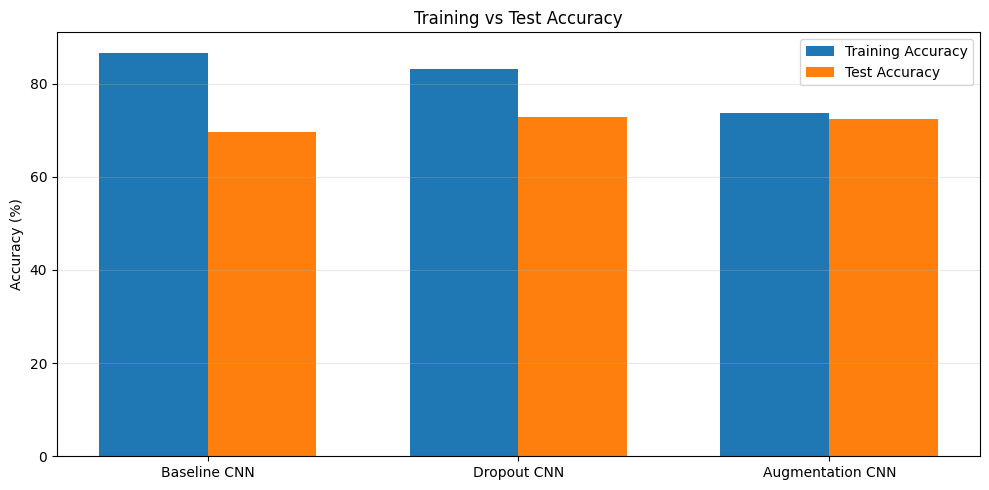

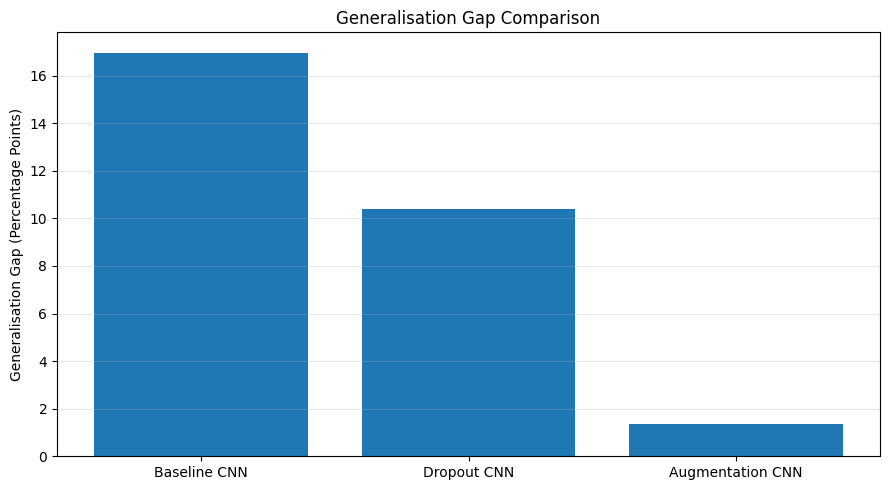

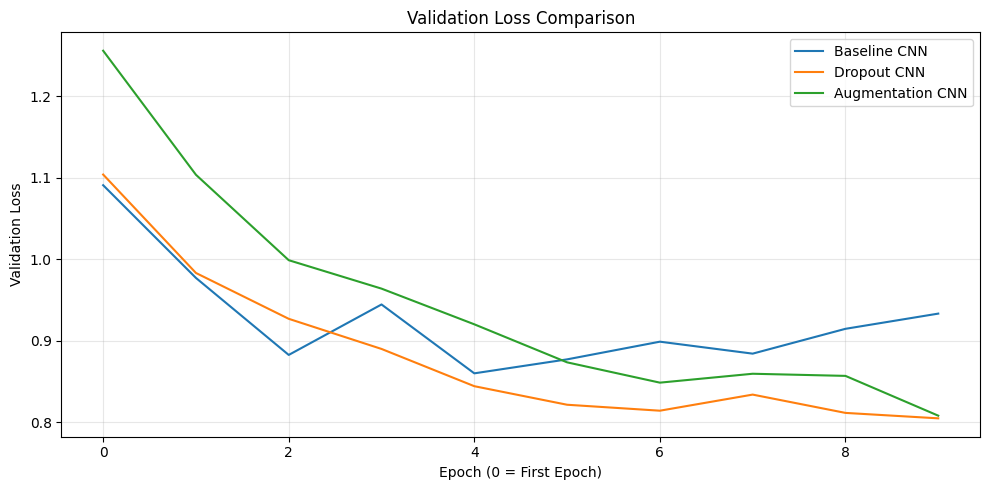

All Exercise 3 comparison graphs saved!


In [17]:

# STEP 13: Comparison Graphs

import matplotlib.pyplot as plt
import numpy as np

models = ["Baseline CNN", "Dropout CNN", "Augmentation CNN"]

train_acc = [
    baseline_train_acc,
    dropout_train_acc,
    augmentation_train_acc
]

test_acc = [
    baseline_test_acc,
    dropout_test_acc,
    augmentation_test_acc
]

gaps = [
    baseline_gap,
    dropout_gap,
    augmentation_gap
]

x = np.arange(len(models))
width = 0.35

# Graph 1: Training vs Test Accuracy
plt.figure(figsize=(10, 5))

plt.bar(x - width/2, train_acc, width, label="Training Accuracy")
plt.bar(x + width/2, test_acc, width, label="Test Accuracy")

plt.xticks(x, models)
plt.ylabel("Accuracy (%)")
plt.title("Training vs Test Accuracy")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("Exercise3_Accuracy_Comparison.png", dpi=300)
plt.show()

# Graph 2: Generalisation Gap
plt.figure(figsize=(9, 5))

plt.bar(models, gaps)

plt.ylabel("Generalisation Gap (Percentage Points)")
plt.title("Generalisation Gap Comparison")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("Exercise3_Generalisation_Gap.png", dpi=300)
plt.show()

# Graph 3: Validation Loss
plt.figure(figsize=(10, 5))

plt.plot(baseline_history["val_loss"], label="Baseline CNN")
plt.plot(dropout_history["val_loss"], label="Dropout CNN")
plt.plot(augmentation_history["val_loss"], label="Augmentation CNN")

plt.xlabel("Epoch (0 = First Epoch)")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Exercise3_Validation_Loss.png", dpi=300)
plt.show()

print("All Exercise 3 comparison graphs saved!")


In [19]:
# STEP 14: Final Results Table

import pandas as pd

results_df = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "CNN + Dropout",
        "CNN + Data Augmentation"
    ],
    "Training Accuracy (%)": [
        baseline_train_acc,
        dropout_train_acc,
        augmentation_train_acc
    ],
    "Test Accuracy (%)": [
        baseline_test_acc,
        dropout_test_acc,
        augmentation_test_acc
    ],
    "Generalisation Gap (pp)": [
        baseline_gap,
        dropout_gap,
        augmentation_gap
    ],
    "Test Loss": [
        baseline_test_loss,
        dropout_test_loss,
        augmentation_test_loss
    ],
    "Parameters": [
        total_params,
        dropout_params,
        augmentation_params
    ]
})

print("Exercise 3 - Final Comparison")
print(results_df.round(2).to_string(index=False))

results_df.to_csv(
    "Exercise3_Final_Results.csv",
    index=False
)

print("\nFinal results saved successfully!")

Exercise 3 - Final Comparison
                  Model  Training Accuracy (%)  Test Accuracy (%)  Generalisation Gap (pp)  Test Loss  Parameters
           Baseline CNN                  86.67              69.70                    16.97       0.95       60362
          CNN + Dropout                  83.15              72.76                    10.39       0.80       60362
CNN + Data Augmentation                  73.69              72.33                     1.36       0.81       60362

Final results saved successfully!


In [21]:

# STEP 16: Verify Dataset Split

from torch.utils.data import random_split

generator = torch.Generator().manual_seed(42)

check_train, check_val = random_split(
    full_train_dataset,
    [40000, 10000],
    generator=generator
)

train_match = list(check_train.indices) == list(train_indices)
val_match = list(check_val.indices) == list(val_indices)

print("Training Split Matches:", train_match)
print("Validation Split Matches:", val_match)

assert train_match and val_match, "Dataset split mismatch!"

print("Dataset split verification successful!")


Training Split Matches: True
Validation Split Matches: True
Dataset split verification successful!


### Exercise 3 – Results and Discussion

The experiment compared the baseline CNN with two regularisation methods: dropout and data augmentation.

The baseline model achieved 86.67% training accuracy and 69.70% test accuracy, with a generalisation gap of 16.97 percentage points. This indicates overfitting.

Using dropout (p = 0.3), test accuracy increased to 72.76%, and the generalisation gap decreased to 10.39 percentage points. The results suggest that dropout reduced overfitting and improved generalisation.

Data augmentation, using random cropping and horizontal flipping, achieved 72.33% test accuracy. Its generalisation gap was only 1.36 percentage points, indicating similar performance on training and test images. However, its lower training accuracy of 73.69% suggests that the model learned the training data less completely within the 10 training epochs.

Overall, both regularisation techniques improved test accuracy compared with the baseline. Dropout achieved the highest test accuracy, while data augmentation produced the smallest generalisation gap. The results show that the choice of regularisation method involves a trade-off between training performance and generalisation.
